# Imputing missing values before building an estimator — scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/impute/plot_missing_values.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
(gallery: https://scikit-learn.org/dev/auto_examples/impute/plot_missing_values.html).

**Scenario:** remove values from the first 300 rows of the diabetes data (75 % of rows lose one
feature), then score `make_pipeline(imputer, RandomForestRegressor(random_state=0))` with
`cross_val_score(..., scoring="neg_mean_squared_error", cv=4)` for zero imputation
(`SimpleImputer(strategy="constant", fill_value=0, add_indicator=True)`), mean imputation
(`SimpleImputer(strategy="mean", add_indicator=True)`), `KNNImputer(add_indicator=True)` and
`IterativeImputer(add_indicator=True)`.

**Adaptations:**
- The California housing half of the example downloads data (`fetch_california_housing`); it is
  skipped. Only the bundled diabetes data is used, so the `RobustScaler` pre-step the example
  applies to California is not exercised.
- The forests use `random_state=0` on both sides; Moxie's forest replays the same bootstrap and
  feature-sampling stream, so per-fold scores are compared directly. The same pipelines are also
  scored with a deterministic `LinearRegression` final step, which isolates the imputers.
- Imputer outputs, learned statistics and feature names are compared against the pinned
  `sklearn/impute/_base.py` and `_knn.py` bodies (the installed wheel is 1.9.1; the pinned source wins).
- Moxie's `RandomForestRegressor` takes `NDArray[float32]` features (scikit-learn casts to float32
  inside `fit`), so the Moxie forest pipelines use `SimpleImputer[DType.float32]` /
  `KNNImputer[DType.float32]` on float32-cast data; a Float64 imputer cannot feed a Moxie forest.
  The deterministic `LinearRegression` pipelines stay Float64.
- `IterativeImputer` is deferred in Moxie; its step is recorded as a GAP with an expect-fail cell.

**Determinism:** the reference is deterministic (fixed `RandomState(42)` for the missing mask,
`random_state=0` for the forests, unshuffled `KFold(4)`).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("impute/plot_missing_values")

## 1. scikit-learn (Python reference)

The official example code, diabetes half only.

In [2]:
import numpy as np

from sklearn.datasets import load_diabetes

X_diabetes, y_diabetes = load_diabetes(return_X_y=True)
X_diabetes = X_diabetes[:300]
y_diabetes = y_diabetes[:300]


def add_missing_values(X_full, y_full, rng):
    n_samples, n_features = X_full.shape

    # Add missing values in 75% of the lines
    missing_rate = 0.75
    n_missing_samples = int(n_samples * missing_rate)

    missing_samples = np.zeros(n_samples, dtype=bool)
    missing_samples[:n_missing_samples] = True

    rng.shuffle(missing_samples)
    missing_features = rng.randint(0, n_features, n_missing_samples)
    X_missing = X_full.copy()
    X_missing[missing_samples, missing_features] = np.nan
    y_missing = y_full.copy()

    return X_missing, y_missing


rng = np.random.RandomState(42)
X_miss_diabetes, y_miss_diabetes = add_missing_values(X_diabetes, y_diabetes, rng)
print("missing entries:", int(np.isnan(X_miss_diabetes).sum()))

missing entries: 225


In [3]:
from sklearn.ensemble import RandomForestRegressor

# To use the experimental IterativeImputer, we need to explicitly ask for it:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

N_SPLITS = 4


def get_score(X, y, imputer=None):
    regressor = RandomForestRegressor(random_state=0)
    if imputer is not None:
        estimator = make_pipeline(imputer, regressor)
    else:
        estimator = regressor
    scores = cross_val_score(
        estimator, X, y, scoring="neg_mean_squared_error", cv=N_SPLITS
    )
    return scores.mean(), scores.std()


x_labels = []
mses_diabetes = np.zeros(5)
stds_diabetes = np.zeros(5)

mses_diabetes[0], stds_diabetes[0] = get_score(X_diabetes, y_diabetes)
x_labels.append("Full Data")

imputer = SimpleImputer(strategy="constant", fill_value=0, add_indicator=True)
mses_diabetes[1], stds_diabetes[1] = get_score(X_miss_diabetes, y_miss_diabetes, imputer)
x_labels.append("Zero Imputation")

imputer = SimpleImputer(strategy="mean", add_indicator=True)
mses_diabetes[2], stds_diabetes[2] = get_score(X_miss_diabetes, y_miss_diabetes, imputer)
x_labels.append("Mean Imputation")

imputer = KNNImputer(add_indicator=True)
mses_diabetes[3], stds_diabetes[3] = get_score(X_miss_diabetes, y_miss_diabetes, imputer)
x_labels.append("KNN Imputation")

imputer = IterativeImputer(add_indicator=True)
mses_diabetes[4], stds_diabetes[4] = get_score(X_miss_diabetes, y_miss_diabetes, imputer)
x_labels.append("Iterative Imputation")

mses_diabetes = mses_diabetes * -1
for label, mse, std in zip(x_labels, mses_diabetes, stds_diabetes):
    print(f"{label:22s} MSE {mse:9.1f} +/- {std:7.1f}")

Full Data              MSE    3179.5 +/-   112.0
Zero Imputation        MSE    3296.7 +/-   184.5
Mean Imputation        MSE    3274.2 +/-   212.2
KNN Imputation         MSE    3378.5 +/-   182.4
Iterative Imputation   MSE    3200.3 +/-   151.8


Deterministic reference for parity: the pinned `_base.py` / `_knn.py` imputer bodies on the full
missing data, and the same pipelines with a `LinearRegression` final step under the same
`cross_val_score(..., cv=4)`.

In [4]:
import importlib.util
import warnings
from sklearn.linear_model import LinearRegression

SK = ROOT.parent / "scikit-learn"


def pinned(rel, name):
    spec = importlib.util.spec_from_file_location(name, SK / rel)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


base = pinned("sklearn/impute/_base.py", "sklearn.impute._pinned_base")
knn = pinned("sklearn/impute/_knn.py", "sklearn.impute._pinned_knn")
PinnedSimple, PinnedKNN = base.SimpleImputer, knn.KNNImputer

ref_imputers = {
    "zero": PinnedSimple(strategy="constant", fill_value=0, add_indicator=True),
    "mean": PinnedSimple(strategy="mean", add_indicator=True),
    "knn": PinnedKNN(add_indicator=True),
}
ref = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for key, est in ref_imputers.items():
        ref[key + "_out"] = est.fit_transform(X_miss_diabetes)
        ref[key + "_names"] = list(est.get_feature_names_out())
        ref[key + "_features"] = est.indicator_.features_
        ref[key + "_linear"] = cross_val_score(
            make_pipeline(est, LinearRegression()), X_miss_diabetes, y_miss_diabetes,
            scoring="neg_mean_squared_error", cv=N_SPLITS)
        ref[key + "_forest"] = cross_val_score(
            make_pipeline(est, RandomForestRegressor(random_state=0)), X_miss_diabetes,
            y_miss_diabetes, scoring="neg_mean_squared_error", cv=N_SPLITS)
    ref["mean_statistics"] = ref_imputers["mean"].statistics_
    ref["full_forest"] = cross_val_score(RandomForestRegressor(random_state=0), X_diabetes,
                                         y_diabetes, scoring="neg_mean_squared_error", cv=N_SPLITS)
print("output shapes:", {k: ref[k + "_out"].shape for k in ref_imputers})
print("linear neg-MSE:", {k: ref[k + "_linear"].round(2) for k in ref_imputers})
nb.share(X_miss=X_miss_diabetes, y=y_miss_diabetes, X_full=X_diabetes)

output shapes: {'zero': (300, 20), 'mean': (300, 20), 'knn': (300, 20)}
linear neg-MSE: {'zero': array([-2973.52, -3424.37, -3568.26, -3679.81]), 'mean': array([-2973.52, -3424.37, -3568.26, -3679.81]), 'knn': array([-3042.29, -3612.18, -3590.01, -3668.85])}


## 2. Moxie (native Mojo)

Imputers fitted on the missing data; outputs, statistics and feature names saved.

In [5]:
%%mojo imputers
from moxie.impute import SimpleImputer, KNNImputer
from moxie_nb_io import load, save, save_ints, save_strings


def main() raises:
    var X = load("X_miss")
    var zero = SimpleImputer(strategy="constant", fill_value=Float64(0), add_indicator=True)
    save("zero_out", zero.fit_transform(X))
    save_strings("zero_names", zero.get_feature_names_out())
    save_ints("zero_features", zero.indicator_.value().features_)
    var mean = SimpleImputer(strategy="mean", add_indicator=True)
    save("mean_out", mean.fit_transform(X))
    save_strings("mean_names", mean.get_feature_names_out())
    save_ints("mean_features", mean.indicator_.value().features_)
    save("mean_statistics", mean.statistics_)
    var knn = KNNImputer(add_indicator=True)
    save("knn_out", knn.fit_transform(X))
    save_strings("knn_names", knn.get_feature_names_out())
    save_ints("knn_features", knn.indicator_.value().features_)
    print("n_features_in_:", zero.n_features_in_, mean.n_features_in_, knn.n_features_in_)

n_features_in_: 10 10 10


The same pipelines under `moxie.model_selection.cross_val_score` with unshuffled `KFold(4)`
(sklearn's `cv=4` for regressors) and a negative-MSE scorer. Each fold clones the unfitted
pipeline, so this also exercises `clone` through `Pipeline[imputer, regressor]`.

In [6]:
%%mojo cv_scores
from numojo import NDArray, Shape, Item
from moxie.base import SupervisedEstimator, Predictor, clone
from moxie.ensemble import RandomForestRegressor
from moxie.impute import SimpleImputer, KNNImputer
from moxie.linear_model import LinearRegression
from moxie.model_selection import KFold, IndexArray, IndexSplit, cross_val_score
from moxie.model_selection._evaluation import TypedScorer
from moxie.model_selection._validation import CVAdapter
from moxie.pipeline import make_pipeline
from moxie_nb_io import load, save

comptime Dense = NDArray[DType.float64]


def take_rows[d: DType](X: NDArray[d], rows: IndexArray) raises -> NDArray[d]:
    var out = NDArray[d](Shape(rows.size, X.shape[1]))
    for i in range(rows.size):
        for j in range(X.shape[1]):
            out[Item(i, j)] = X[Item(Int(rows[Item(i)]), j)]
    return out^


def take_values(y: Dense, rows: IndexArray) raises -> Dense:
    var out = Dense(Shape(rows.size))
    for i in range(rows.size):
        out[Item(i)] = y[Item(Int(rows[Item(i)]))]
    return out^


struct NegMSE[E: SupervisedEstimator & Predictor & Deinitable, d: DType = DType.float64](TypedScorer):
    # scoring="neg_mean_squared_error"
    comptime Estimator = Self.E
    comptime Input = NDArray[Self.d]
    comptime Target = Dense
    comptime Metadata = Optional[Dense]

    def __init__(out self):
        pass

    def score(self, estimator: Self.E, X: NDArray[Self.d], y: Dense, metadata: Optional[Dense]) raises -> Float64:
        var prediction = rebind_var[Dense](estimator.predict(rebind[Self.E.Input](X)))
        ref truth = y
        var total = Float64(0)
        for i in range(truth.size):
            var d = prediction[Item(i)] - truth[Item(i)]
            total += d * d
        return -total / Float64(truth.size)


struct Rows[E: SupervisedEstimator & Predictor & Deinitable, d: DType = DType.float64](CVAdapter):
    comptime Scorer = NegMSE[Self.E, Self.d]

    def __init__(out self):
        pass

    def n_samples(self, X: NDArray[Self.d], y: Dense) raises -> Int:
        return X.shape[0]

    def input_rows(self, X: NDArray[Self.d], rows: IndexArray, train: IndexArray) raises -> NDArray[Self.d]:
        return take_rows(X, rows)

    def target_rows(self, y: Dense, rows: IndexArray) raises -> Dense:
        return take_values(y, rows)

    def metadata_rows(self, metadata: Optional[Dense], rows: IndexArray) raises -> Optional[Dense]:
        return None

    def fit(self, mut estimator: Self.E, X: NDArray[Self.d], y: Dense, metadata: Optional[Dense]) raises:
        _ = estimator.fit(rebind[Self.E.Input](X), rebind[Self.E.Target](y))


def folds(n: Int) raises -> List[IndexSplit]:
    var cursor = KFold(4).split(n)
    var out = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        out.append(pair.value().copy())
    return out^


def score[E: SupervisedEstimator & Predictor & Deinitable, d: DType = DType.float64](name: String, estimator: E, X: NDArray[d], y: Dense) raises:
    var values = cross_val_score[Rows[E, d]](
        estimator, X, y, Rows[E, d](), NegMSE[E, d](), folds(X.shape[0]), None, None)
    save(name, values)


def main() raises:
    var X = load("X_miss")
    var X_full = load("X_full")
    var y = load("y")
    score("zero_linear", make_pipeline(SimpleImputer(strategy="constant", fill_value=Float64(0), add_indicator=True), LinearRegression()), X, y)
    score("mean_linear", make_pipeline(SimpleImputer(strategy="mean", add_indicator=True), LinearRegression()), X, y)
    score("knn_linear", make_pipeline(KNNImputer(add_indicator=True), LinearRegression()), X, y)
    # Moxie forests take Float32 features (sklearn casts to float32 inside fit),
    # so the forest pipelines impute in Float32; a Float64 imputer cannot feed them.
    var X32 = X.astype[DType.float32]()
    score("zero_forest", make_pipeline(SimpleImputer[DType.float32](strategy="constant", fill_value=Float32(0), add_indicator=True), RandomForestRegressor(random_state=0)), X32, y)
    score("mean_forest", make_pipeline(SimpleImputer[DType.float32](strategy="mean", add_indicator=True), RandomForestRegressor(random_state=0)), X32, y)
    score("knn_forest", make_pipeline(KNNImputer[DType.float32](add_indicator=True), RandomForestRegressor(random_state=0)), X32, y)
    score("full_forest", RandomForestRegressor(random_state=0), X_full.astype[DType.float32](), y)
    var fitted = make_pipeline(KNNImputer(add_indicator=True), LinearRegression())
    _ = fitted.fit(X, y)
    var fresh = clone(fitted)
    print("pipeline fitted:", fitted.__sklearn_is_fitted__(), "clone fitted:", fresh.__sklearn_is_fitted__())

pipeline fitted: True clone fitted: False


`IterativeImputer` is a deferred declaration in Moxie; constructing it raises a clear error.

In [7]:
%%mojo iterative --expect-fail
from moxie.impute import IterativeImputer


def main() raises:
    _ = IterativeImputer(add_indicator=True)

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: IterativeImputer.__init__ is an API scaffold



## 3. Side by side and parity

,sklearn MSE,moxie MSE
imputer,,
Full Data,3179.5,3179.5
Zero Imputation,3296.7,3296.7
Mean Imputation,3274.2,3274.2
KNN Imputation,3378.5,3377.6


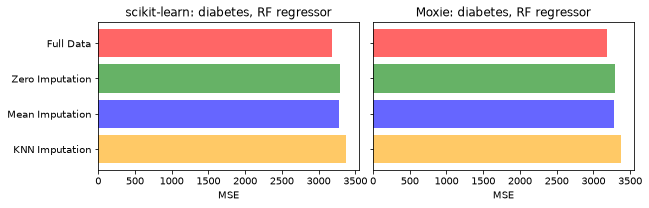

In [8]:
import matplotlib.pyplot as plt

mx = nb.results["imputers"]
cv = nb.results["cv_scores"]
for key in ("zero", "mean", "knn"):
    # Same Float64 algorithms; mean differs only in summation order, KNN in the
    # distance formula (direct sum over observed coordinates vs sklearn's norm expansion).
    nb.compare(f"{key} fit_transform", ref[key + "_out"], mx[key + "_out"], rtol=1e-12, atol=1e-14,
               reason="Float64 reduction order (mean) and nan_euclidean evaluation order (KNN)")
    nb.compare(f"{key} indicator_.features_", ref[key + "_features"], mx[key + "_features"], exact=True)
    nb.compare(f"{key} get_feature_names_out", np.array(ref[key + "_names"]), np.array(mx[key + "_names"]), exact=True)
    nb.compare(f"{key}+LinearRegression neg-MSE per fold", ref[key + "_linear"], cv[key + "_linear"],
               rtol=1e-8, reason="least-squares solver differs (LAPACK gelsd vs Moxie's solver) on the same imputed design")
nb.compare("mean statistics_", ref["mean_statistics"], mx["mean_statistics"], rtol=1e-12, atol=1e-15,
           reason="Float64 summation order")

rows = []
for key, label in (("full", "Full Data"), ("zero", "Zero Imputation"), ("mean", "Mean Imputation"), ("knn", "KNN Imputation")):
    sk_mse, mx_mse = -ref[key + "_forest"].mean(), -cv[key + "_forest"].mean()
    rows.append((label, sk_mse, mx_mse))
    # Moxie's forest replays sklearn's RandomState(0) bootstrap stream on the same Float32
    # features, so per-fold scores agree to rounding when the imputed Float32 inputs are identical.
    # KNN imputes in Float32 in Moxie (the forest only accepts Float32), whereas sklearn imputes in
    # Float64 and casts; last-ulp differences move a few split thresholds.
    if key == "knn":
        nb.compare(f"{label} forest neg-MSE per fold", ref[key + "_forest"], cv[key + "_forest"], rtol=2e-3,
                   reason="Float32 KNN imputation vs sklearn's Float64-then-cast changes a few tree splits")
    else:
        nb.compare(f"{label} forest neg-MSE per fold", ref[key + "_forest"], cv[key + "_forest"], rtol=1e-9,
                   reason="same bootstrap stream and Float32 features; tree-sum order differs")
nb.note("Iterative Imputation", "GAP", "IterativeImputer is a deferred declaration; its constructor raises NotImplementedError")
nb.note("California housing", "GAP", "dataset requires a download; skipped (adaptation, not a Moxie gap)")

import pandas as pd
table = pd.DataFrame(rows, columns=["imputer", "sklearn MSE", "moxie MSE"]).set_index("imputer")
moxie_nb.side_by_side(sklearn=ref["mean_out"][:4, -4:], moxie=mx["mean_out"][:4, -4:])
display(table.round(1))

fig, axes = plt.subplots(1, 2, figsize=(9, 3), dpi=72, sharex=True)
colors = ["r", "g", "b", "orange"]
for ax, column, title in ((axes[0], "sklearn MSE", "scikit-learn"), (axes[1], "moxie MSE", "Moxie")):
    ax.barh(range(len(table)), table[column], color=colors, alpha=0.6)
    ax.set_yticks(range(len(table)))
    ax.set_yticklabels(table.index if ax is axes[0] else [""] * len(table))
    ax.invert_yaxis()
    ax.set_title(f"{title}: diabetes, RF regressor")
    ax.set_xlabel("MSE")
plt.tight_layout()
plt.show()

In [9]:
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
zero fit_transform,PASS,"(300, 20)","(300, 20)",0,0,"rtol=1e-12, atol=1e-14",,Float64 reduction order (mean) and nan_euclidean evaluation order (KNN)
zero indicator_.features_,PASS,"(10,)","(10,)",,,exact,0 mismatches,
zero get_feature_names_out,PASS,"(20,)","(20,)",,,exact,0 mismatches,
zero+LinearRegression neg-MSE per fold,PASS,"(4,)","(4,)",1.47e-10,4.96e-14,"rtol=1e-08, atol=0",,least-squares solver differs (LAPACK gelsd vs Moxie's solver) on the same imputed design
mean fit_transform,PASS,"(300, 20)","(300, 20)",9.97e-18,2.25e-14,"rtol=1e-12, atol=1e-14",,Float64 reduction order (mean) and nan_euclidean evaluation order (KNN)
mean indicator_.features_,PASS,"(10,)","(10,)",,,exact,0 mismatches,
mean get_feature_names_out,PASS,"(20,)","(20,)",,,exact,0 mismatches,
mean+LinearRegression neg-MSE per fold,PASS,"(4,)","(4,)",6.46e-11,2.17e-14,"rtol=1e-08, atol=0",,least-squares solver differs (LAPACK gelsd vs Moxie's solver) on the same imputed design
knn fit_transform,PASS,"(300, 20)","(300, 20)",2.78e-17,8.71e-15,"rtol=1e-12, atol=1e-14",,Float64 reduction order (mean) and nan_euclidean evaluation order (KNN)
knn indicator_.features_,PASS,"(10,)","(10,)",,,exact,0 mismatches,
